<a href="https://colab.research.google.com/github/damourmaniragaba/INFO-2950-Project/blob/main/Phase2_Part1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# __Final Project Phase 2: Part 1__
### What makes a successful trader on Polymarket?

Ha An Pham Le (hp482), Alanna (ay444), Jean D'Amour Maniragaba (jm2876)

# __RESEARCH QUESTIONS__

**Main question:** Which characteristics of a position, and which behaviors of a trader, are associated with higher returns on Polymarket, the largest prediction market?

**Sub-questions**
1. **Position level:** Is a position's return related to its **entry price**, **category** (sports, politics, crypto, weather, tech, culture, econ), **size**, **holding time**, and the **event's trading volume**?
2. **Trader level:** Is a trader's return related to how much of their money they put on **sports**, how much **risk** they take, how **focused** they are on a few categories, how **often** they trade, and how **long** they have been on Polymarket, after accounting for whether they are a **leaderboard (top) trader** or an **ordinary trader**?

**How we measure success: return on investment (ROI)**
- ROI = profit or loss ÷ money spent on the position.
- A Polymarket contract pays 1 if the outcome happens and 0 if it does not. So a contract bought at price *p* returns $(1-p)/p$ if it wins and $-1$ if it loses.
- We use ROI instead of dollar profit because dollar profit mostly tells us how much money a trader has, not how good their trades are.

**Our two models**
- *Position level:* ROI = α + β₁highRisk + β₂lowRisk + β₃log(CostBasis) + β₄log(HoldingDays) + β₅log(EventVolume) + β₆politics + β₇crypto + β₈weather + β₉tech + β₁₀culture + β₁₁econ + β₁₂other + ε

(Reference categories: mediumRisk and sports)

- *Trader level:* traderROI = α + β₁highRiskShare + β₂categoryHHI + β₃positionsPerMonth + β₄tenure + β₅log(totalSpent) + β₆topTrader + β₇sportsShare + ε


# __DEFINITIONS__
- Prediction market - A website where people buy and sell shares on whether future events will happen
- Event / market - a topic (e.g., "who will win the 2026 NBA Finals?"); can contain several markets, each a single yes/no question
- Share / contract - pays \$1 if its outcome happens and \$0 if not, so its price (\$0 to \$1) works like the market's estimated probability
- Position - all of one wallet's shares in one outcome of one market, from the first purchase until it is sold or the market ends
- Resolve / redeem - a market resolves when the outcome is decided; traders then cash in winning shares for \$1 each
- Wallet - a trading account, identified by an address on the blockchain; we occasionally refer to a wallet as a "trader" for convenience, but it's possible for one trader to have multiple wallets
- Leaderboard - Polymarket's public ranking of wallets by profit
- PnL (Profit and Loss) - how much money a position or trader made or lost
- ROI (Return on Investment) - profit or loss ÷ money spent
- Cost basis - money spent on a position (shares bought * average price)
- Volume - Total dollar amount traded on an event by everyone
- HHI | Herfindahl-Hirschman Index: a 0-to-1 measure of how concentrated something is (here, a trader's money across categories)



# __DATA COLLECTION__

**Source.** All data comes from Polymarket's two free, public APIs (no key needed):
- the **Data API** (https://data-api.polymarket.com/v2) for the leaderboard, trades, positions, and user stats;
- the **Gamma API** (https://gamma-api.polymarket.com) for each event's tags and trading volume.

Polymarket records every trade on the Polygon blockchain, so the data can be checked against public records.

**How we built the sample**
1. **Top traders:** the 1,000 wallets with the highest all-time profit on the leaderboard.
2. **Random traders:** we listed 2,000 events that closed between Oct 1, 2025 and Oct 1, 2026 and randomly picked 1,500 of them. For each, we took one random trader from the most recent trades in the event's first market, excluding top traders. We kept the first 1,000 different wallets.
3. **Positions:** for each of the 2,000 wallets, we downloaded up to 500 of its most recent positions for each of three statuses:
   - `CLOSED`: sold or cashed in;
   - `REDEEMABLE`: the market resolved and the trader still holds the shares;
   - `REDEEMABLE_LOST`: the market resolved and the trader lost.
   
   We only kept positions with activity between Oct 1, 2025 and Oct 1, 2026. We need all three statuses because a losing bet held to the end is worth \$0, so traders often never cash it in. If we only downloaded `CLOSED` positions, many losses would be missing.
4. **Join dates** for each wallet, from `/user-stats`.
5. **Event information** (tags and volume) for every event in our positions, from the Gamma API.

The collection code is below; running it takes over 1 hour. It saves five raw files in `data/` (748,733 raw positions and 132,844 events). The cleaning section only reads those files, so the download only needs to run once. After cleaning, 1,849 of the 2,000 wallets still have at least one position, so the trader table has 1,849 rows.

Data collected on 10/11/2026.

### Setup
Imports, the two API addresses, and our time window (Oct 1, 2025 to Oct 1, 2026, written in epoch seconds because that is the format the API uses).

In [1]:
# Create data directory
!mkdir -p data

# imports and settings
import requests
import numpy as np
import pandas as pd
import duckdb
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 6.0)

DATA_API = 'https://data-api.polymarket.com/v2'
GAMMA_API = 'https://gamma-api.polymarket.com'
START = 1759276800   # Oct 1, 2025 in epoch seconds
END = 1790812800     # Oct 1, 2026 in epoch seconds

### Data collection code
`get_json` sends one request to the API and returns the response. If the request fails, it returns `None`, and the loops below skip that request.

In [2]:
def get_json(url, params=None):
    response = requests.get(url, params=params)
    if response.status_code == 200:
        return response.json()
    return None

**Top traders:** the 1000 wallets with the highest all-time profit on the leaderboard.

In [3]:
# Collection 1: top 1000 traders by all-time profit
leaderboard = get_json(DATA_API + '/leaderboard', {'time_period': 'all', 'sort_by': 'PNL', 'limit': 1000})
leaderboard_df = pd.DataFrame(leaderboard['data'])
leaderboard_df['proxy_wallet'] = leaderboard_df['user_id'].str.lower()
leaderboard_df.to_csv('data/leaderboard_raw.csv', index=False)
print(leaderboard_df.shape)
leaderboard_df[['rank', 'proxy_wallet', 'pnl']].head()

(1000, 9)


,rank,proxy_wallet,pnl
0,1,0x56687bf447db6ffa42ffe2204a05edaa20f55839,2.205393e+07
1,2,0x204f72f35326db932158cba6adff0b9a1da95e14,1.841817e+07
2,3,0x1f2dd6d473f3e824cd2f8a89d9c69fb96f6ad0cf,1.661951e+07
3,4,0x2005d16a84ceefa912d4e380cd32e7ff827875ea,1.296728e+07
4,5,0x6a72f61820b26b1fe4d956e17b6dc2a1ea3033ee,1.135141e+07


**Closed events:** 2,000 events that closed in our window. For each one we keep its first market's id (`condition_id`), which we need in order to look up that market's trades.

In [4]:
# Collection 2: list 2,000 events that closed inside our time window
event_rows = []
for offset in range(0, 2000, 100):
    events = get_json(GAMMA_API + '/events', {'closed': 'true', 'limit': 100, 'offset': offset,
                                             'end_date_min': '2025-10-01T00:00:00Z',
                                             'end_date_max': '2026-10-01T00:00:00Z'})
    if events is None:
        break
    for event in events:
        if event.get('markets'):
            event_rows.append({'event_id': event['id'], 'condition_id': event['markets'][0]['conditionId']})

closed_events_df = pd.DataFrame(event_rows)
print(closed_events_df.shape)
closed_events_df.head()

(2000, 2)


,event_id,condition_id
0,14375,0xe3ece9fd2b3ec7bc3c1c0e2ba034f42ccbe20fe65b92...
1,15082,0xfc0feefc275cd9588dbbe54cced3e9f25ae2b0687efe...
2,15586,0x37e6c1227c1ee562cbd906099dadbd658ddca8cdb973...
3,15625,0xd9ce9f9f9b9c193c06b8fbab9284a3b5de28570ba213...
4,15633,0x19f0ff3845b991bf9561aa81f7a23d88a607a437a6ec...


**Random traders:** for 1500 randomly chosen closed markets, we pick one random trader who is not a top trader. Then we remove repeats and keep 1000.

In [5]:
# Collection 3: one random non-top trader from each of 1,500 random markets
top_wallets = leaderboard_df['proxy_wallet'].tolist()
sampled_markets = closed_events_df.sample(min(1500, len(closed_events_df)), random_state=2950)

random_wallets = []
for condition_id in sampled_markets['condition_id']:
    trades = get_json(DATA_API + '/trades', {'condition': condition_id, 'limit': 100})
    if trades is None or len(trades['data']) == 0:
        continue
    trades_df = pd.DataFrame(trades['data'])
    trades_df['proxy_wallet'] = trades_df['proxy_wallet'].str.lower()
    trades_df = trades_df[~trades_df['proxy_wallet'].isin(top_wallets)]
    if len(trades_df) > 0:
        random_wallets.append(trades_df.sample(1, random_state=2950)['proxy_wallet'].iloc[0])

random_wallets = pd.Series(random_wallets).drop_duplicates().head(1000).tolist()
print('random wallets:', len(random_wallets))

random wallets: 1000


**Wallet list:** both groups in one table, with a column saying which group each wallet belongs to.

In [6]:
# Collection 4: one table with every sampled wallet and its group
top_df = pd.DataFrame({'proxy_wallet': top_wallets, 'sample_group': 'leaderboard'})
random_df = pd.DataFrame({'proxy_wallet': random_wallets, 'sample_group': 'random'})
wallets_df = pd.concat([top_df, random_df], ignore_index=True)
wallets_df.to_csv('data/wallets_raw.csv', index=False)
wallets_df['sample_group'].value_counts()
wallets_df.head()

,proxy_wallet,sample_group
0,0x56687bf447db6ffa42ffe2204a05edaa20f55839,leaderboard
1,0x204f72f35326db932158cba6adff0b9a1da95e14,leaderboard
2,0x1f2dd6d473f3e824cd2f8a89d9c69fb96f6ad0cf,leaderboard
3,0x2005d16a84ceefa912d4e380cd32e7ff827875ea,leaderboard
4,0x6a72f61820b26b1fe4d956e17b6dc2a1ea3033ee,leaderboard


**Positions:** for each wallet and each of the three statuses, up to 500 of the most recent positions inside our window.

In [7]:
# Collection 5: positions for every wallet (3 statuses, up to 500 each)
position_frames = []
for i, wallet in enumerate(wallets_df['proxy_wallet']):
    for status in ['CLOSED', 'REDEEMABLE', 'REDEEMABLE_LOST']:
        result = get_json(DATA_API + '/positions', {'user': wallet, 'status': status, 'limit': 500,
                                                   'sort_by': 'TIMESTAMP', 'start': START, 'end': END})
        if result is not None and len(result['data']) > 0:
            status_df = pd.DataFrame(result['data'])
            status_df['proxy_wallet'] = wallet
            status_df['query_status'] = status
            position_frames.append(status_df)
    if (i + 1) % 20 == 0:
        print(i + 1, 'wallets done')

positions_raw_df = pd.concat(position_frames, ignore_index=True)
positions_raw_df.to_csv('data/positions_raw.csv', index=False)
print(positions_raw_df.shape)
positions_raw_df.head()

20 wallets done
40 wallets done
60 wallets done
80 wallets done
100 wallets done
120 wallets done
140 wallets done
160 wallets done
180 wallets done
200 wallets done
220 wallets done
240 wallets done
260 wallets done
280 wallets done
300 wallets done
320 wallets done
340 wallets done
360 wallets done
380 wallets done
400 wallets done
420 wallets done
440 wallets done
460 wallets done
480 wallets done
500 wallets done
520 wallets done
540 wallets done
560 wallets done
580 wallets done
600 wallets done
620 wallets done
640 wallets done
660 wallets done
680 wallets done
700 wallets done
720 wallets done
740 wallets done
760 wallets done
780 wallets done
800 wallets done
820 wallets done
840 wallets done
860 wallets done
880 wallets done
900 wallets done
920 wallets done
940 wallets done
960 wallets done
980 wallets done
1000 wallets done
1020 wallets done
1040 wallets done
1060 wallets done
1080 wallets done
1100 wallets done
1120 wallets done
1140 wallets done
1160 wallets done
1180 wall

,proxy_wallet,token_id,condition_id,current_size,avg_price,entry_cost_usdc,entry_fees_usdc,total_cost_usdc,current_price,current_value,...,outcome_index,opposite_outcome,opposite_token_id,end_date,last_event_at,first_entry_at,name,profile_image,verified,query_status
0,0x204f72f35326db932158cba6adff0b9a1da95e14,6400666341593583959977039676538515420954068514...,0xde444dc4022aefc71d25e00f71bd5db0d1a8babcc577...,0.0,0.6171,0.0,0.03626,0.03626,0.0,0.0,...,1,Kiwoom Heroes,2629670793413025955113745064526942751510337878...,2026-07-16,1790749520,1783573225,swisstony,,False,CLOSED
1,0x204f72f35326db932158cba6adff0b9a1da95e14,1103866788387404063436391158674059798340681889...,0xf1eeb99016f4fdd68b1a61320910a71443c51aaa996a...,0.0,0.3900,0.0,0.00000,0.00000,1.0,0.0,...,0,Lotte Giants,3184893613688844409253211292842972234586701487...,2026-10-04,1790585759,1776415774,swisstony,,False,CLOSED
2,0x204f72f35326db932158cba6adff0b9a1da95e14,3341836805726939455975643458452584921735092037...,0x13c04fc860cff263f0d390c11c704600a1accf7aec2c...,0.0,0.4200,0.0,0.00000,0.00000,1.0,0.0,...,0,KT Wiz,8898217078804805745460513184174893261184577648...,2026-06-21,1790412987,1781420632,swisstony,,False,CLOSED
3,0x204f72f35326db932158cba6adff0b9a1da95e14,8898217078804805745460513184174893261184577648...,0x13c04fc860cff263f0d390c11c704600a1accf7aec2c...,0.0,0.5703,0.0,0.03676,0.03676,0.0,0.0,...,1,NC Dinos,3341836805726939455975643458452584921735092037...,2026-06-21,1790412987,1781421700,swisstony,,False,CLOSED
4,0x204f72f35326db932158cba6adff0b9a1da95e14,4464982143236125584195266369772617064836499365...,0x563c2fca6a8516bcbd40b51163d0d20bd05fcdc568c9...,0.0,0.3980,0.0,0.00000,0.00000,0.0,0.0,...,1,Yes,5218099765135773212702712484845144100759242885...,2026-07-25,1790126380,1784936115,swisstony,,False,CLOSED


In [8]:
# Convert all date and timestamp columns in positions_raw_df to proper datetime objects
if 'first_entry_at' in positions_raw_df.columns:
    positions_raw_df['first_entry_at'] = pd.to_datetime(positions_raw_df['first_entry_at'], unit='s')
if 'last_event_at' in positions_raw_df.columns:
    positions_raw_df['last_event_at'] = pd.to_datetime(positions_raw_df['last_event_at'], unit='s')
if 'end_date' in positions_raw_df.columns:
    positions_raw_df['end_date'] = pd.to_datetime(positions_raw_df['end_date'])

display(positions_raw_df[['first_entry_at', 'last_event_at', 'end_date']].head())

,first_entry_at,last_event_at,end_date
0,2026-07-09 05:00:25,2026-09-30 06:25:20,2026-07-16
1,2026-04-17 08:49:34,2026-09-28 08:55:59,2026-10-04
2,2026-06-14 07:03:52,2026-09-26 08:56:27,2026-06-21
3,2026-06-14 07:21:40,2026-09-26 08:56:27,2026-06-21
4,2026-07-24 23:35:15,2026-09-23 01:19:40,2026-07-25


**Join dates:** used to measure how long each wallet has been trading.

In [9]:
# Collection 6: join date for every wallet
stats_rows = []
for wallet in wallets_df['proxy_wallet']:
    result = get_json(DATA_API + '/user-stats', {'user': wallet})
    join_date = None
    if result is not None and result['data'] is not None:
        join_date = result['data'].get('join_date')
    stats_rows.append({'proxy_wallet': wallet, 'join_date': join_date})

user_stats_df = pd.DataFrame(stats_rows)
user_stats_df.to_csv('data/user_stats_raw.csv', index=False)
print(user_stats_df.shape)
user_stats_df.head()

(2000, 2)


,proxy_wallet,join_date
0,0x56687bf447db6ffa42ffe2204a05edaa20f55839,1.728882e+09
1,0x204f72f35326db932158cba6adff0b9a1da95e14,1.753800e+09
2,0x1f2dd6d473f3e824cd2f8a89d9c69fb96f6ad0cf,1.719036e+09
3,0x2005d16a84ceefa912d4e380cd32e7ff827875ea,1.734021e+09
4,0x6a72f61820b26b1fe4d956e17b6dc2a1ea3033ee,1.750284e+09


In [10]:
if 'join_date' in user_stats_df.columns:
   user_stats_df['join_date'] = pd.to_datetime(user_stats_df['join_date'], unit='s')

display(user_stats_df.head())

,proxy_wallet,join_date
0,0x56687bf447db6ffa42ffe2204a05edaa20f55839,2024-10-14 04:57:11
1,0x204f72f35326db932158cba6adff0b9a1da95e14,2025-07-29 14:46:06
2,0x1f2dd6d473f3e824cd2f8a89d9c69fb96f6ad0cf,2024-06-22 05:58:34
3,0x2005d16a84ceefa912d4e380cd32e7ff827875ea,2024-12-12 16:25:53
4,0x6a72f61820b26b1fe4d956e17b6dc2a1ea3033ee,2025-06-18 21:55:05


**Event information:** tags and trading volume for every event that appears in our positions, requested 20 events at a time.

In [12]:
# Collection 7: tags and volume for every event in our positions (20 per request)
event_ids = positions_raw_df['event_id'].dropna().astype(str).unique().tolist()
event_rows = []
for i in range(0, len(event_ids), 20):
    events = get_json(GAMMA_API + '/events', {'id': event_ids[i:i + 20]})
    if events is None:
        continue
    for event in events:
        tags = ''
        if event.get('tags') is not None:
            for tag in event['tags']:
                tags = tags + ' ' + str(tag.get('slug'))
        if event.get('category') is not None:
            tags = tags + ' ' + event['category']
        tags = tags.strip()
        event_rows.append({'event_id': str(event['id']),
                           'event_title': event.get('title'),
                           'event_volume': event.get('volume'),
                            'tags': tags if tags else 'none'})

events_raw_df = pd.DataFrame(event_rows)
events_raw_df.to_csv('data/events_raw.csv', index=False)
print(events_raw_df.shape)
display(events_raw_df.head())

(132321, 4)


,event_id,event_title,event_volume,tags
0,367654,KBO: Hanwha Eagles vs. Lotte Giants,2.055371e+04,sports games baseball kbo
1,437856,KBO: Lotte Giants vs. KT Wiz,1.037921e+04,sports games baseball kbo
2,494880,Tampa Bay Rays vs. New York Yankees,4.298201e+06,sports games mlb baseball
3,572644,KBO: NC Dinos vs. KT Wiz,2.568058e+04,sports games baseball kbo
4,629454,Yokohama BayStars vs. Yomiuri Giants,5.168389e+02,sports games baseball npb


# __DATA CLEANING APPENDIX__

Starting from the raw files, this section creates two analysis-ready files:
- `positions_clean.csv`: **one row per position**;
- `traders_clean.csv`: **one row per trader**.

**Step 1: Load the raw files.** We read `event_id` and `token_id` as text: they are ids, not numbers.

In [13]:
# Step 1: load the raw files saved during data collection
wallets_df = pd.read_csv('data/wallets_raw.csv')
positions_df = pd.read_csv('data/positions_raw.csv', dtype={'event_id': str, 'token_id': str})
user_stats_df = pd.read_csv('data/user_stats_raw.csv')
events_df = pd.read_csv('data/events_raw.csv', dtype={'event_id': str})

# Ensure all date-like strings and unix epoch timestamps are formatted as datetime types
if 'end_date' in positions_df.columns:
    positions_df['end_date'] = pd.to_datetime(positions_df['end_date'])
if 'join_date' in user_stats_df.columns:
    user_stats_df['join_date'] = pd.to_datetime(user_stats_df['join_date'], unit='s')

print('wallets:', wallets_df.shape)
print('positions:', positions_df.shape)
print('user stats:', user_stats_df.shape)
print('events:', events_df.shape)

wallets: (2000, 2)
positions: (745709, 37)
user stats: (2000, 2)
events: (132321, 4)


**Step 2: Keep only the columns we need.** We drop the other ~25 columns, including profile information like display names and profile pictures, which we do not need and which make traders easier to identify.

In [14]:
# Step 2: keep only the columns we use
positions_df = positions_df[['proxy_wallet', 'query_status', 'token_id', 'condition_id', 'event_id', 'title',
                             'avg_price', 'total_size', 'total_pnl', 'first_entry_at', 'last_event_at']]
positions_df.head()

,proxy_wallet,query_status,token_id,condition_id,event_id,title,avg_price,total_size,total_pnl,first_entry_at,last_event_at
0,0x204f72f35326db932158cba6adff0b9a1da95e14,CLOSED,6400666341593583959977039676538515420954068514...,0xde444dc4022aefc71d25e00f71bd5db0d1a8babcc577...,662475,KBO: Kiwoom Heroes vs. KT Wiz,0.6171,5.0819,-3.1362,1783573225,1790749520
1,0x204f72f35326db932158cba6adff0b9a1da95e14,CLOSED,1103866788387404063436391158674059798340681889...,0xf1eeb99016f4fdd68b1a61320910a71443c51aaa996a...,367654,KBO: Hanwha Eagles vs. Lotte Giants,0.3900,156.0000,95.1600,1776415774,1790585759
2,0x204f72f35326db932158cba6adff0b9a1da95e14,CLOSED,3341836805726939455975643458452584921735092037...,0x13c04fc860cff263f0d390c11c704600a1accf7aec2c...,572644,KBO: NC Dinos vs. KT Wiz,0.4200,244.0000,141.5200,1781420632,1790412987
3,0x204f72f35326db932158cba6adff0b9a1da95e14,CLOSED,8898217078804805745460513184174893261184577648...,0x13c04fc860cff263f0d390c11c704600a1accf7aec2c...,572644,KBO: NC Dinos vs. KT Wiz,0.5703,115.0000,-65.5866,1781421700,1790412987
4,0x204f72f35326db932158cba6adff0b9a1da95e14,CLOSED,4464982143236125584195266369772617064836499365...,0x563c2fca6a8516bcbd40b51163d0d20bd05fcdc568c9...,739614,Birmingham Legion FC vs. New Mexico United: Bo...,0.3980,40.9966,-16.3186,1784936115,1790126380


**Step 3: Remove duplicates.** A position is one wallet holding one outcome token. The same resolved position can show up under both `REDEEMABLE` and `REDEEMABLE_LOST`, so we keep only one copy.

In [15]:
# Step 3: remove duplicate positions (same wallet and same token)
print('before:', len(positions_df))
positions_df = positions_df.drop_duplicates(subset=['proxy_wallet', 'token_id'])
print('after:', len(positions_df))

before: 745709
after: 612956


**Step 4: Money spent and unusable rows.**
- **Money spent** on a position (`cost_basis`) = shares bought (`total_size`) × average buying price (`avg_price`).
- We remove rows whose price is not between \$0 and \$1 (not a valid price) and rows with no profit/loss

In [16]:
# Step 4: money spent, then remove unusable rows
positions_df['cost_basis'] = positions_df['total_size'] * positions_df['avg_price']

positions_df = positions_df[(positions_df['avg_price'] > 0) & (positions_df['avg_price'] < 1)]
print('after removing invalid prices:', len(positions_df))
positions_df = positions_df.dropna(subset=['total_pnl'])
print('after removing missing profit:', len(positions_df))
positions_df.head()

after removing invalid prices: 610701
after removing missing profit: 610701


,proxy_wallet,query_status,token_id,condition_id,event_id,title,avg_price,total_size,total_pnl,first_entry_at,last_event_at,cost_basis
0,0x204f72f35326db932158cba6adff0b9a1da95e14,CLOSED,6400666341593583959977039676538515420954068514...,0xde444dc4022aefc71d25e00f71bd5db0d1a8babcc577...,662475,KBO: Kiwoom Heroes vs. KT Wiz,0.6171,5.0819,-3.1362,1783573225,1790749520,3.136040
1,0x204f72f35326db932158cba6adff0b9a1da95e14,CLOSED,1103866788387404063436391158674059798340681889...,0xf1eeb99016f4fdd68b1a61320910a71443c51aaa996a...,367654,KBO: Hanwha Eagles vs. Lotte Giants,0.3900,156.0000,95.1600,1776415774,1790585759,60.840000
2,0x204f72f35326db932158cba6adff0b9a1da95e14,CLOSED,3341836805726939455975643458452584921735092037...,0x13c04fc860cff263f0d390c11c704600a1accf7aec2c...,572644,KBO: NC Dinos vs. KT Wiz,0.4200,244.0000,141.5200,1781420632,1790412987,102.480000
3,0x204f72f35326db932158cba6adff0b9a1da95e14,CLOSED,8898217078804805745460513184174893261184577648...,0x13c04fc860cff263f0d390c11c704600a1accf7aec2c...,572644,KBO: NC Dinos vs. KT Wiz,0.5703,115.0000,-65.5866,1781421700,1790412987,65.584500
4,0x204f72f35326db932158cba6adff0b9a1da95e14,CLOSED,4464982143236125584195266369772617064836499365...,0x563c2fca6a8516bcbd40b51163d0d20bd05fcdc568c9...,739614,Birmingham Legion FC vs. New Mexico United: Bo...,0.3980,40.9966,-16.3186,1784936115,1790126380,16.316647


**Step 5: ROI.**
- **ROI** = profit or loss (`total_pnl`) ÷ money spent (`cost_basis`).
- **Check:** a share bought at price *p* can be worth at most \$1 and at least \$0. So ROI must be between **−1** and **(1 − p)/p**. Rows outside that range (with a small 0.01 allowance for rounding) contradict how contracts work, so we remove them.
- `won` is True when ROI is above 0.

In [17]:
# Step 5: ROI, remove impossible values, and mark winning positions
positions_df['roi'] = positions_df['total_pnl'] / positions_df['cost_basis']
positions_df['max_roi'] = (1 - positions_df['avg_price']) / positions_df['avg_price']
positions_df = positions_df[(positions_df['roi'] >= -1.01) & (positions_df['roi'] <= positions_df['max_roi'] + 0.01)].copy()
positions_df['won'] = positions_df['roi'] > 0
print('after removing impossible ROI values:', len(positions_df))
print(positions_df['roi'].describe())

after removing impossible ROI values: 579160
count    579160.000000
mean          0.588729
std          11.959227
min          -1.010000
25%          -1.000000
50%           0.001001
75%           0.279021
max         999.000000
Name: roi, dtype: float64


**Step 6: Holding time.** The number of days from the first purchase to the last activity on the position. Negative values are data errors, so we set them to missing (`NaN`).

In [18]:
# Step 6: holding time in days (86,400 seconds in a day)
positions_df['holding_days'] = (positions_df['last_event_at'] - positions_df['first_entry_at']) / 86400
positions_df.loc[positions_df['holding_days'] < 0, 'holding_days'] = np.nan

# Convert raw timestamp epoch seconds columns directly to datetime objects
positions_df['first_entry_at'] = pd.to_datetime(positions_df['first_entry_at'], unit='s')
positions_df['last_event_at'] = pd.to_datetime(positions_df['last_event_at'], unit='s')

print('missing holding time:', positions_df['holding_days'].isna().sum())
positions_df[['first_entry_at', 'last_event_at', 'holding_days']].head()

missing holding time: 0


,first_entry_at,last_event_at,holding_days
0,2026-07-09 05:00:25,2026-09-30 06:25:20,83.058970
1,2026-04-17 08:49:34,2026-09-28 08:55:59,164.004456
2,2026-06-14 07:03:52,2026-09-26 08:56:27,104.078183
3,2026-06-14 07:21:40,2026-09-26 08:56:27,104.065822
4,2026-07-24 23:35:15,2026-09-23 01:19:40,60.072512


**Step 7: Price groups.** Each position goes into one of three groups by entry price:
- **highRisk:** under \$0.20 (the market thinks it is unlikely);
- **mediumRisk:** \$0.20 to \$0.80;
- **lowRisk:** \$0.80 or more (the market thinks it is likely).

In [19]:
# Step 7: price group for each position
def price_group(price):
    if price < 0.2:
        return 'highRisk'
    elif price < 0.8:
        return 'mediumRisk'
    else:
        return 'lowRisk'

positions_df['price_group'] = positions_df['avg_price'].apply(price_group)
positions_df['price_group'].value_counts()

,count
price_group,
mediumRisk,295812
lowRisk,156522
highRisk,126826


**Step 8: Categories.**
- Each event has tags such as `nba`, `elections` or `bitcoin`. We give each event one of our seven categories .by checking its tags against the main categories on Polymarket's homepage (listed in MAIN_TAGS below)
- If an event matches more than one category, we check them in a fixed order from most to least specific (crypto, sports, weather, econ, tech, culture, politics). For example, "Will Bitcoin hit \$150k before the election?" counts as **crypto**.
- Events that match nothing are **other**.

In [20]:
# Step 8: Polymarket's homepage category tags, grouped into our 7 categories (checked in this order)
MAIN_TAGS = {
    'crypto': ['crypto'],
    'sports': ['sports', 'esports'],
    'weather': ['weather'],
    'econ': ['economy', 'finance'],
    'tech': ['tech'],
    'culture': ['pop-culture', 'mentions'],
    'politics': ['politics', 'geopolitics', 'elections'],
}

def get_category(tags):
    words = str(tags).lower().split()
    for category in MAIN_TAGS:
        for tag in MAIN_TAGS[category]:
            if tag in words:
                return category
    return 'other'

events_df['category'] = events_df['tags'].apply(get_category)
events_df['category'].value_counts(normalize=True)

,proportion
category,
crypto,0.457599
sports,0.408801
weather,0.039646
politics,0.036714
econ,0.031658
culture,0.017458
tech,0.006144
other,0.001980


**Step 9: Merge everything onto the positions.**
- **Trader ids:** we give each wallet a simple number (`trader_id`) and then drop the wallet address, so the clean file does not list people's addresses (privacy & cleaner table).
- **Group:** an inner join adds each position's group (`leaderboard` or `random`).
- **Events:** a left join adds each position's category and event volume. Positions whose event was not found are labeled **unknown**.
- **Zero volume:** an event that our traders bought into cannot really have \$0 of trading volume, so we treat a volume of 0 as missing.


In [21]:
# Step 9: add trader ids, group, category, and event volume, then save the clean position table
wallets_df['trader_id'] = np.arange(1, len(wallets_df) + 1)
positions_df = positions_df.merge(wallets_df, on='proxy_wallet', how='inner')
positions_df = positions_df.merge(events_df[['event_id', 'category', 'event_volume']], on='event_id', how='left')
positions_df['category'] = positions_df['category'].fillna('unknown')

# an event that has positions can't have $0 of volume, so we treat 0 as missing (the log of 0 is undefined)
print('positions with $0 event volume:', (positions_df['event_volume'] == 0).sum())
positions_df.loc[positions_df['event_volume'] == 0, 'event_volume'] = np.nan

positions_clean_df = positions_df.drop(columns=['proxy_wallet', 'max_roi'])
positions_clean_df.to_csv('data/positions_clean.csv', index=False)
print(positions_clean_df.shape)
positions_clean_df.drop(columns=['token_id', 'condition_id']).head()

positions with $0 event volume: 3
(579160, 19)


,query_status,event_id,title,avg_price,total_size,total_pnl,first_entry_at,last_event_at,cost_basis,roi,won,holding_days,price_group,sample_group,trader_id,category,event_volume
0,CLOSED,662475,KBO: Kiwoom Heroes vs. KT Wiz,0.6171,5.0819,-3.1362,2026-07-09 05:00:25,2026-09-30 06:25:20,3.136040,-1.000051,False,83.058970,mediumRisk,leaderboard,2,sports,12297.268086
1,CLOSED,367654,KBO: Hanwha Eagles vs. Lotte Giants,0.3900,156.0000,95.1600,2026-04-17 08:49:34,2026-09-28 08:55:59,60.840000,1.564103,True,164.004456,mediumRisk,leaderboard,2,sports,20553.713206
2,CLOSED,572644,KBO: NC Dinos vs. KT Wiz,0.4200,244.0000,141.5200,2026-06-14 07:03:52,2026-09-26 08:56:27,102.480000,1.380952,True,104.078183,mediumRisk,leaderboard,2,sports,25680.584850
3,CLOSED,572644,KBO: NC Dinos vs. KT Wiz,0.5703,115.0000,-65.5866,2026-06-14 07:21:40,2026-09-26 08:56:27,65.584500,-1.000032,False,104.065822,mediumRisk,leaderboard,2,sports,25680.584850
4,CLOSED,739614,Birmingham Legion FC vs. New Mexico United: Bo...,0.3980,40.9966,-16.3186,2026-07-24 23:35:15,2026-09-23 01:19:40,16.316647,-1.000120,False,60.072512,mediumRisk,leaderboard,2,sports,4135.716028


**Step 10: Trader table.** We use SQL to collapse the positions into **one row per trader**:

| Column | Meaning |
|---|---|
| `n_positions` | number of positions |
| `total_spent` | total money spent |
| `total_pnl` | total profit or loss |
| `trader_roi` | total profit ÷ total money spent |
| `win_rate` | share of positions that made money |
| `highRisk_share` | share of money spent on highRisks (under \$0.20). **Our measure of risk:** cheap contracts rarely pay off, so the more money on them, the riskier the trader. |
| `median_holding_days` | median days a position is held |


In [24]:
# Step 10: one row per trader, using SQL
traders_df = duckdb.sql("SELECT trader_id, sample_group, COUNT(*) AS n_positions, \
    SUM(cost_basis) AS total_spent, SUM(total_pnl) AS total_pnl, \
    SUM(total_pnl) / SUM(cost_basis) AS trader_roi, \
    AVG(CASE WHEN won THEN 1 ELSE 0 END) AS win_rate, \
    SUM(CASE WHEN avg_price < 0.2 THEN cost_basis ELSE 0 END) / SUM(cost_basis) \
    AS highRisk_share, \
    SUM(CASE WHEN category = 'sports' THEN cost_basis ELSE 0 END) / \
    SUM(cost_basis) AS sports_share, \
    MEDIAN(holding_days) AS median_holding_days \
    FROM positions_clean_df GROUP BY trader_id, sample_group ORDER BY trader_id").df()
traders_df.head()

,trader_id,sample_group,n_positions,total_spent,total_pnl,trader_roi,win_rate,highRisk_share,sports_share,median_holding_days
0,2,leaderboard,500,4.983443e+04,8.346303e+03,0.167481,0.486000,0.035217,1.000000,5.598738
1,4,leaderboard,981,1.972486e+06,-9.905570e+04,-0.050219,0.320082,0.037659,1.000000,0.145150
2,5,leaderboard,536,1.942073e+07,-5.840867e+06,-0.300754,0.427239,0.000642,1.000000,0.882934
3,6,leaderboard,5,8.648808e+06,9.110690e+06,1.053404,1.000000,0.000000,1.000000,0.173218
4,7,leaderboard,923,1.089770e+08,4.698328e+06,0.043113,0.433369,0.042636,0.999232,0.183113


**Step 11: Category focus (CategoryHHI).** This measures how focused a trader is on a few categories:
1. For each trader, find the share of their money in each category.
2. Square each share and add them up.

The result is **1** if all their money is in one category, and about **0.14** if it is spread evenly over all seven. We skip `unknown` positions so that missing data does not look like spreading out.

In [25]:
# Step 11: category focus (HHI) for each trader
known_df = positions_clean_df[positions_clean_df['category'] != 'unknown']
category_spent = known_df.groupby(['trader_id', 'category'])['cost_basis'].sum().reset_index()
trader_spent = known_df.groupby('trader_id')['cost_basis'].sum().reset_index()
trader_spent = trader_spent.rename(columns={'cost_basis': 'trader_total'})

category_spent = category_spent.merge(trader_spent, on='trader_id')
category_spent['share_squared'] = (category_spent['cost_basis'] / category_spent['trader_total']) ** 2
hhi_df = category_spent.groupby('trader_id')['share_squared'].sum().reset_index()
hhi_df = hhi_df.rename(columns={'share_squared': 'category_hhi'})
hhi_df.head()

,trader_id,category_hhi
0,2,1.000000
1,4,1.000000
2,5,1.000000
3,6,1.000000
4,7,0.998465


**Step 12: Tenure, trading frequency, and the final trader table.**
- **Tenure:** months from the wallet's join date to Oct 1, 2026.
- **Positions per month:** the number of positions in our one-year window ÷ 12.
- **`top_trader`:** 1 for leaderboard wallets, 0 for random wallets.

In [26]:
# Step 12: add tenure, positions per month, and the top-trader dummy, then save the clean trader table
user_stats_df = user_stats_df.merge(wallets_df[['proxy_wallet', 'trader_id']], on='proxy_wallet')

# Convert END epoch seconds to a pandas Timestamp to calculate change in time
end_datetime = pd.to_datetime(END, unit='s')
user_stats_df['tenure_months'] = (end_datetime - user_stats_df['join_date']).dt.total_seconds() / (86400 * 30.44)
#86400 is # of seconds in a day and 30.44 is the avg # of days in a month

# Keep a readable copy of the join date
user_stats_df['join_date_readable'] = user_stats_df['join_date']

traders_df = traders_df.merge(hhi_df, on='trader_id', how='left')
traders_df = traders_df.merge(user_stats_df[['trader_id', 'tenure_months', 'join_date_readable']], on='trader_id', how='left')
traders_df['positions_per_month'] = traders_df['n_positions'] / 12
traders_df['top_trader'] = (traders_df['sample_group'] == 'leaderboard').astype(int)

traders_clean_df = traders_df.copy()
traders_clean_df.to_csv('data/traders_clean.csv', index=False)
print(traders_clean_df.shape)
traders_clean_df[['trader_id', 'join_date_readable', 'tenure_months']].head()

(1844, 15)


,trader_id,join_date_readable,tenure_months
0,2,2025-07-29 14:46:06,14.073083
1,4,2024-12-12 16:25:53,21.593803
2,5,2025-06-18 21:55:05,15.410209
3,6,2026-06-02 14:47:45,3.954780
4,7,2026-01-22 23:17:23,8.246702


# __DATA DESCRIPTION__

### __MOTIVATION__
__Why was this dataset created?__

- Polymarket provides this public API so developers and users can read wallet-level portfolios, trade feeds, market states, and leaderboards. This is important because they believe when forecasters or just a lot of people in general risk money on their opinions, it actually creates accurate real-world data and sentiment (since there is money on the line, people have to have expertise and be honest, so we know the crowds' knowledge and honest predictions about all these topics they're trading in). Therefore, we can look at this dataset and see patterns of people's behaviors/predictions in relation with the actual events to learn about their accuracy, their perception, etc. The founder basically wanted to fight misinformation with Polymarket. By opening up this transparent data, they turn their market probabilities into a free public tool for researchers, traders, and market makers.
- On a more business-oriented standpoint, it is to scale to more users since it increases reliability and credibility, so they know they can trust it with their money. It can also reach to more developers who can help them build features they might be missing because the data is free and public.

__How did you create this dataset? What tools, procedures, and data
sources did you use?__

- Our group created this dataset using Polymarket's public APIs based on their international markets.
- We credit Polymarket for making its trading data free and openly available, the Polygon blockchain for recording every trade publicly, and UMA, the system Polymarket uses to decide how markets resolve.
- We acquired this dataset with Python's `requests` library calling Polymarket's Data API and Gamma API (see Data Collection). Every value was recorded by Polymarket when the trade happened. We only calculated new columns (ROI, holding time, categories, HHI). The data includes positions with activity from Oct 1, 2025 to Oct 1, 2026.

### __COMPOSITION__
__What are the observations (rows) and the attributes (columns)?__

`positions_clean.csv`: one row per position, i.e., one trader's holdings in one outcome (e.g., "Yes") of one market, with activity between Oct 1, 2025 and Oct 1, 2026.
- `trader_id`: the number we assigned to each trader in place of their wallet address
- `sample_group`: which sample the trader came from (leaderboard or random)
- `query_status`: the position's status
  * CLOSED: sold or cashed in
  * REDEEMABLE: market resolved, shares still held
  * REDEEMABLE_LOST: market resolved and trader lost
- `token_id`: ID of the outcome the trader bought
- `condition_id`: ID of the market the outcome belongs to
- `event_id`: ID of the event the market belongs to (one event can have multiple markets)
- `title`: the market's question
- `avg_price`: average price paid per share (\$0–\$1)
- `total_size`: number of shares purchased
- `cost_basis`: money spent on the position in dollars (`total_size` * `avg_price`)
- `total_pnl`: total_pnl: profit or loss on this position, in dollars (PnL = profit and loss)
- `roi`: return on investment (`total_pnl` / `cost_basis`)
- `won`: whether an investment made money
- `first_entry_at`: first purchase time (originally in epoch seconds, converted to datetime in clean file)
- `last_event_at`: last activity time (originally in epoch seconds, converted to datetime in clean file)
- `holding_days`: days held
- `price_group`: highRisk (under \$0.20), mediumRisk, or lowRisk (\$0.80 or more)
- `category`: the event's category (crypto, sports, weather, econ, tech, culture, politics)
  * "other" if none of the tags match
  * "unknown" if we have no event information
- `event_volume`: the event's total trading volume across all traders, in dollars

`traders_clean.csv`: one row per trader, built by summarizing trader's rows in `positions_clean.csv`
- `trader_id`
- `sample_group`
- `n_positions`: number of positions the trader has in our data
- `total_spent`: total money spent across all positions, in dollars (sum of `cost_basis`)
- `total_pnl`: total profit or loss across all of the trader's positions, in dollars
- `trader_roi`: overall return on investment (`total_pnl` ÷ `total_spent`)
- `win_rate`: share of the trader's positions that made money
- `highRisk_share`: share of the trader's money spent on contracts priced under \$0.20; our measure of risk-taking
- `median_holding_days`: median number of days the trader held a position
- `category_hhi`: how focused the trader is on few categories (0 to 1; 1 means all money in one category). It is the sum of the squared shares of money spent in each category, leaving out "unknown"
- `tenure_months`: months from the trader's Polymarket join date to Oct 1, 2026
- `join_date_readable`: the date the trader joined Polymarket
- `positions_per_month`: the average number of positions per month in our one-year window (`n_positions` / 12)
- `top_trader`: 1 if the trader is from the leaderboard, 0 if from the random sample


### __COLLECTION PROCESS__
__What processes might have influenced what data was observed and recorded and what was not?__

- Polymarket decides which markets exist and how they're tagged, so the categories we used reflects its choices.
- The leaderboard ranks by profit, so our top group is chosen by the very thing we're studying.
- Random traders were picked from recent trades in random markets, so it's likely that wallets that trade a lot are more likely to be picked.
- We downloaded at most 500 positions per status per wallet, so for very active wallets we only see their most recent positions.

__What preprocessing was done, and how did the data come to be in the form we are using?__

  We started by removing duplicates, invalid prices, missing profits, and impossible ROI values. Then, we calculated ROI, holding time, price groups, and categories. After that, we replaced wallets with trader numbers so that the table is cleaner and also to help preserve traders' privacy. Finally, we summarized positions into one row per trader. As previously mentioned, rows describe real people's gains and losses, so we replaced wallet addresses with simple numbers and dropped names.

### __PEOPLE AND USES__
__If people are involved, were they aware of the data collection, and what purpose did they expect the data to be used for?__

  Upon joining Polymarket, traders agree to term and conditions stating that their usernames, profits, losses, and trade, are public on the blockchain,.
  However, since they were not told about our project, we removed information like usernames to help preserve their privacy
  Either way, only Polymarket activity is visible, so we don't know anything about traders' personal identities.

__Where can the raw source data be found?__
- Raw files (`data/*_raw.csv`): https://drive.google.com/drive/folders/1qBlrM1k48SQcTbSTcElOIv_jracyIzQe
- Original source: Polymarket Data API documentation, https://docs.polymarket.com/api-reference/data-api/overview

# __DATA LIMITATIONS__

- The random group isn't completely random because traders who trade often, and who trade near the end of a market are more likely to be picked. This means the non-leaderboard group is still probably more skilled than the average user, so the real gap between top and ordinary traders is probably larger than what we find.
- It's possible that there's some survivorship bias in our data, as traders who quit before October 2025 are not in our random group. Once again, this means our trader groups look more successful than Polymarket users overall.
- Our project treats each wallet as a trader (we also use the word "wallet" and "trader" interchangeably), but the reality is that one person can use several wallets. Someone who splits their trading across wallets could look more focused than they really are.
- It's likely that top wallets are bots, given the very high amount of trades they make per day.
- Positions are not independent because positions by the same trader share that trader's skill, and positions in the same market share the same outcome. This means our uncertainty estimates may look more precise than they really are.
- We thought about an `isCombos` variable for the position-level model, which is like a parlay-style bet where you trade on multiple events to potentially win bigger, but we were researching and found out the Combos feature only launched around June 10, 2026, which is about 4 of our 12 months of data, and Combos only covers trades in the sports category, so it is hard to analyze with the other categories or group in the same model. This might be a limitation because we were thinking whether the player traded in a combo or not could be a predictor to ROI.
- Missing data is not evenly spread out. Event volume is missing for about 4.6% of positions, but mostly in crypto (13.9% of crypto positions, under 3% for every other category), and more often for leaderboard positions (5.9%) than random ones (3.0%). Since these positions are dropped from the position model, that model slightly under-represents crypto and leaderboard trading.
- Tenure months are missing for 4.9% of traders, mostly random traders (7.4% vs. 2.1% for leaderboard traders). These traders are dropped from the trader model, so the random group there is a bit smaller and may leave out a certain kind of trader, such as newer wallets, which would make the random group's tenure look longer than it really is.


__Potential harms__
- Although we stress that we're not trying to give advice, it's possible that results from our project could read like suggestions. Our work might still encourage gambling, especially since our data tends to show more successful traders and trades, as mentioned in the first limitation.
- There are ethical concerns with analyzing markets pertaining to predicting wars, disasters, deaths, and controversial topics. We do not analyze them separately, but they're included in our category averages.

# __EXPLORATORY ANALYSIS__



### 1. Summary statistics
We chose to show the 1st and 99th percentiles in addition to 25th, 50th, and 75th because money on Polymarket is very unevenly spread.

In [27]:
# Summary statistics for the position-level variables
positions_clean_df[['avg_price', 'cost_basis', 'roi', 'holding_days', 'event_volume']].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).round(2)

,avg_price,cost_basis,roi,holding_days,event_volume
count,579160.00,579160.00,579160.00,579160.00,5.524510e+05
mean,0.52,10173.38,0.59,20.51,4.088706e+07
std,0.33,249083.10,11.96,51.18,3.186550e+08
min,0.00,0.00,-1.01,0.00,1.920000e+00
1%,0.00,0.05,-1.00,0.00,6.563200e+02
25%,0.25,10.00,-1.00,0.12,9.346304e+04
50%,0.51,99.99,0.00,0.61,6.105582e+05
75%,0.83,1266.00,0.28,8.70,3.826457e+06
99%,1.00,139928.23,12.14,259.64,7.040968e+08
max,1.00,60966887.64,999.00,1491.76,4.327989e+09


Observations:
1. Mean & median, standard deviation, distribution shape: Looking at the mean and median of this distribution, we can see how right-skewed it is for the cost basis, ROI, holding days, and event volume.
    * There is especially a big gap from the 50th percentile position costing \$100 and the average (mean) position costing more than \$10k. The standard deviation is also extremely high. This means there is a huge spread for this distribution, and for the trades on the higher end, the traders are putting in disproportionately much more money to trade.
    * The average ROI (58%) doesn't reflect a typical position where it wins nothing (0% ROI, so also loses nothing; this just means they made their investment back), so this again shows the higher end positions win disproportionately more because they dragged the average all the way to 58% while the 50th percentile position wins nothing. The spread for it is very high as well, meaning high variability and less consistency in data for this distribution.
    * For holding days, with the same logic, we know that positions on the higher end are held disproportionately longer than the position in the middle percentile. On average, a position is held for more than 20 days while the typical holding duration is about 14.64 hours (we converted 0.61 days to hours for simplicity). Similar to previous ones, the spread for the holding days distribution is also very high.
    * Average price seems pretty consistent across its mean (0.53) and median (0.52), so its distribution is relatively symmetrical. Event volume is not: the median event has about \$613k of trading volume, while the mean is about \$41 million, so a few huge events pull the average up.
2. 99th percentile & outliers: This skewness is even more intensified when we look at the 99th percentile and maximum positions' cost bases, ROIs, holding days, and event volumes.
    * The 99th percentile position costs about \$138.8k while the 75th percentile only costs about \$1,272, which was already about 12.7 times the median, but now the 99th percentile position is about 1,384 times the median, which is disproportionately disproportionate, not to mention the maximum amount of dollars someone put in for one singular trade is around \$61 million, about 608,000 times the median. This means that the traders spending at the highest end of the distribution are spending extremely disproportionately more, and the positions near the maximum are extreme outliers in the data.
    * We can see the same trend in ROIs, where the maximum ROI is 999, the 99th percentile is 11.74, while the median is 0. Each quartile is a drastic difference towards the higher end since the positions that earned the most earn extremely disproportionately more than a typical position.
    * Same logic for holding days. The longest someone held a position for is over 4 years, the 99th percentile is 8 and a half months, and the median is only 14.64 hours. Just by these conversions of units, we can already see how spread out and extremely right skewed the distribution is.
    * The maximum and 99th percentile seem reasonable for average price (we think this is because the average price is capped at \$1, so there's not really a possibly higher value for it to spread to). Event volume, on the other hand, has a 99th percentile of about \$704 million and a maximum of about \$4.3 billion, so it has extreme outliers like cost basis does.

Because cost basis, holding time, and event volume are all this skewed, we use their natural logs in the position model.

In [28]:
# Summary statistics for the trader-level variables
trader_vars = ['n_positions', 'total_spent', 'trader_roi', 'win_rate', 'highRisk_share',
               'category_hhi', 'positions_per_month', 'tenure_months', 'median_holding_days']
traders_clean_df[trader_vars].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).round(2)

,n_positions,total_spent,trader_roi,win_rate,highRisk_share,category_hhi,positions_per_month,tenure_months,median_holding_days
count,1844.00,1.844000e+03,1844.00,1844.00,1844.00,1844.00,1844.00,1752.00,1844.00
mean,314.08,3.195237e+06,0.10,0.56,0.10,0.71,26.17,16.27,20.06
std,290.63,1.325785e+07,0.62,0.23,0.22,0.29,24.22,10.14,52.06
min,1.00,9.000000e-02,-1.00,0.00,0.00,0.15,0.08,0.13,0.00
1%,1.00,1.817000e+01,-0.88,0.00,0.00,0.17,0.08,1.32,0.00
25%,36.75,4.728180e+03,-0.04,0.42,0.00,0.43,3.06,9.63,0.24
50%,254.50,1.596381e+05,0.01,0.55,0.02,0.76,21.21,14.12,1.29
75%,500.00,1.920600e+06,0.10,0.71,0.07,1.00,41.67,22.31,12.59
99%,1000.00,5.897648e+07,2.47,1.00,1.00,1.00,83.33,58.62,280.90
max,1498.00,3.277416e+08,12.09,1.00,1.00,1.00,124.83,71.52,635.13


For traders, we compare the two groups using the median, because a few very large wallets would pull the mean.

In [29]:
# Median of each trader-level variable, by group
traders_clean_df.groupby('sample_group')[trader_vars].median().round(3)

,n_positions,total_spent,trader_roi,win_rate,highRisk_share,category_hhi,positions_per_month,tenure_months,median_holding_days
sample_group,,,,,,,,,
leaderboard,404.0,1974445.061,0.064,0.559,0.015,1.0,33.667,11.063,0.617
random,161.0,6603.080,-0.011,0.531,0.024,0.5,13.417,16.440,3.195


Observations:
- It seems that wallets on the leaderboard tend to hold more positions, as the median number of positions for the leaderboard is about 2.5 times that of the random group.
- Leaderboard wallets tend to spend far more money than wallets from the random group, with a median of almost two million dollars compared to under \$7,000.
  * Despite this, the median win rate of leaderboard wallets (55.7%) is only about 2.5 percentage points higher than that of the random group (53.2%).
- It was surprising to see that the median tenure of leaderboard wallets is about five months shorter than that of the random group.
- Based on the median HHI, leaderboard wallets tend to focus on a single category, while wallets from the random group typically spread their money over about 2 categories.
- Although we originally thought leaderboard wallets would have been on the platform longer, since the users behind them would be more experienced, we suspect the shorter tenure is because many leaderboard wallets are bots.
- Leaderboard wallets tend to hold their positions for a shorter time: the median is a little over half a day, while wallets from the random group hold their positions for a median of over three days. We suspect this is also bot behavior, since bots can monitor the market constantly and turn positions over quickly.

### 2. Missing data

In [30]:
# positions and traders with missing values
print(f"positions with unknown category: {(positions_clean_df['category'] == 'unknown').mean()}")
print(f"positions missing holding time: {positions_clean_df['holding_days'].isna().mean()}")
print(f"positions missing event volume: {positions_clean_df['event_volume'].isna().mean()}")
print(f"traders missing tenure: {traders_clean_df['tenure_months'].isna().mean()}")

positions with unknown category: 6.906554320049727e-05
positions missing holding time: 0.0
positions missing event volume: 0.04611678983355204
traders missing tenure: 0.049891540130151846


Observations: Overall, the data is mostly complete. Almost no positions are uncategorized (0.007%), and no positions are missing a holding time. However, about 4.6% of positions are missing their event's trading volume, and 90 of the 1,849 traders (4.9%) are missing their tenure.

We decided to conduct more calculations to check whether missing data is spread out or concentrated within specific groups.

In [31]:
# check how missing data is spread out
print(positions_clean_df['event_volume'].isna().groupby(positions_clean_df['sample_group']).mean())
print(positions_clean_df['event_volume'].isna().groupby(positions_clean_df['category']).mean())
print(traders_clean_df['tenure_months'].isna().groupby(traders_clean_df['sample_group']).mean())

sample_group
leaderboard    0.057905
random         0.032050
Name: event_volume, dtype: float64
category
crypto      0.143949
culture     0.020051
econ        0.014692
other       0.005266
politics    0.011525
sports      0.026600
tech        0.008083
unknown     1.000000
weather     0.026379
Name: event_volume, dtype: float64
sample_group
leaderboard    0.020666
random         0.076053
Name: tenure_months, dtype: float64


Observations: Running these calculations reveals that missing data is not evenly spread. The percentage of missing positions from the leaderboard group is about twice that of the random group. For categories, "unknown" shows as 100% missing because those positions have no event information so there's no volume, and are thus automatically dropped out of the position model. Aside from that, crypto takes the lead with around 14% of positions missing information. For tenure, wallets from the random group lack that information about 3.5 times as much as leaderboard wallets.

Dropping these rows would mean our position model underrepresents crypto and leaderboard positions, and the trader model underrepresents wallets from the random group. This is a limitation of our data and something we need to keep in mind as we analyze our results.

### 3. Our outcome: ROI
ROI is what we are trying to explain, so we need to know its shape. We expect many positions at −1 (total losses) and a long tail of big wins. For this plot only, values above the 99th percentile are shown at the 99th percentile so the rest is visible.

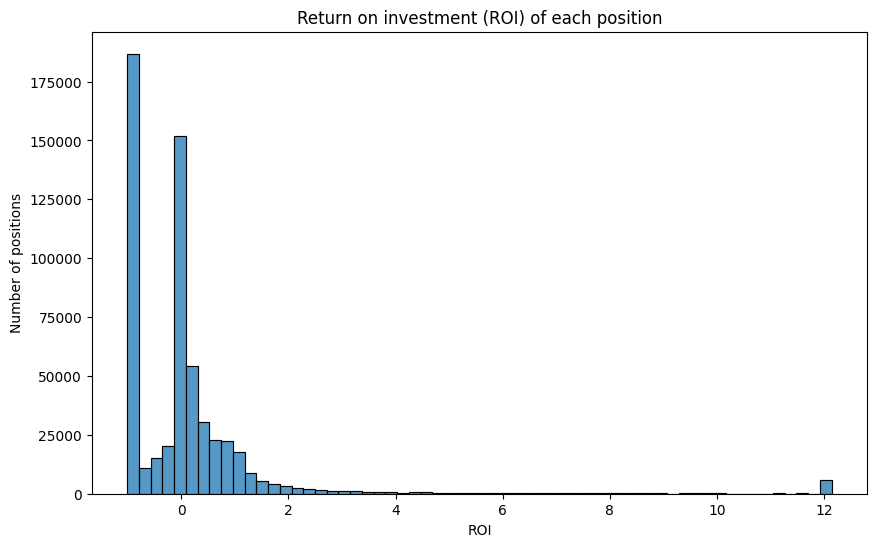

In [32]:
# Distribution of position ROI (top 1% capped for the plot)
roi_99 = positions_clean_df['roi'].quantile(0.99)
sns.histplot(x=positions_clean_df['roi'].clip(upper=roi_99), bins=60)
plt.title('Return on investment (ROI) of each position')
plt.xlabel('ROI')
plt.ylabel('Number of positions')
plt.show()

Observations: Most positions seem to have a ROI near -1, meaning they lost everything, or near 0. The number of positions drops steeply as ROI increases.

There's a small bump at the right edge, as we grouped the top 1% of positions into the last bar. We suspect that the extreme returns come from wins from very cheap shares.

To check that our sample makes sense, leaderboard wallets should earn more than random wallets. If they don't, something went wrong with the data. (The boxplot hides extreme outliers.)

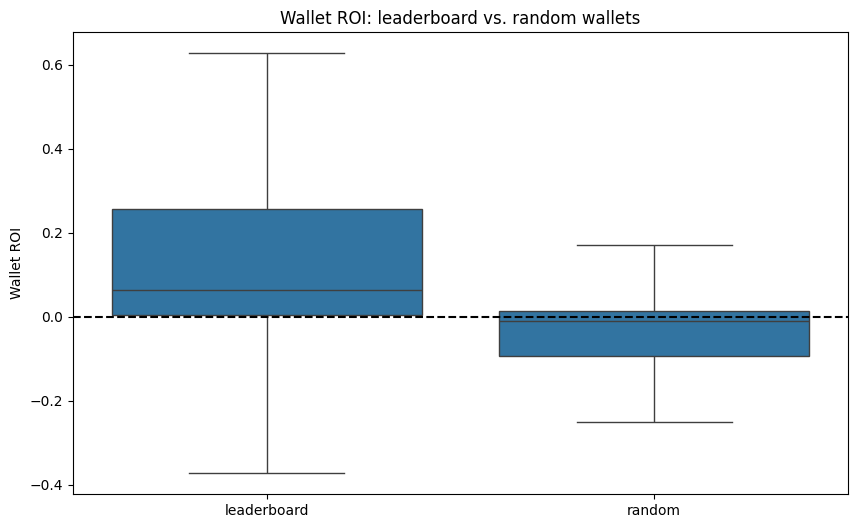

In [33]:
# Trader ROI by group
sns.boxplot(data=traders_clean_df, x='sample_group', y='trader_roi', showfliers=False)
plt.axhline(0, color='black', linestyle='--')
plt.title('Wallet ROI: leaderboard vs. random wallets')
plt.xlabel('')
plt.ylabel('Wallet ROI')
plt.show()

Observations: Unsurprisingly, leaderboard wallets tend to have positive ROI, while wallets from the random group mostly have negative ROI. However, the range of ROI is far greater for leaderboard, with some wallets having significant losses, while the range of ROI for wallets from the random group is much smaller.

The same comparison in numbers, using SQL.

In [34]:
# Average win rate, share of traders who made money, and median ROI by group
duckdb.sql('''
    SELECT sample_group,
           AVG(win_rate) AS avg_win_rate,
           AVG(CASE WHEN trader_roi > 0 THEN 1 ELSE 0 END) AS share_profitable,
           MEDIAN(trader_roi) AS median_roi
    FROM traders_clean_df
    GROUP BY sample_group
''').df().round(3)

,sample_group,avg_win_rate,share_profitable,median_roi
0,leaderboard,0.577,0.777,0.064
1,random,0.543,0.368,-0.011


Observations: The average win rate of leaderboard wallets is only about 3 percentage points higher than that of wallets from the random group (57.6% vs. 54.4%). However, the share of leaderboard wallets that made money (77.7%) is more than twice that of random wallets (36.2%). This matches the median ROI for each group: positive for leaderboard wallets and negative for wallets from the random group.

### 4. Entry prices
Entry price is the basis of our risk measure. We check where each group buys, and whether there are enough positions in each price group to run our analysis.

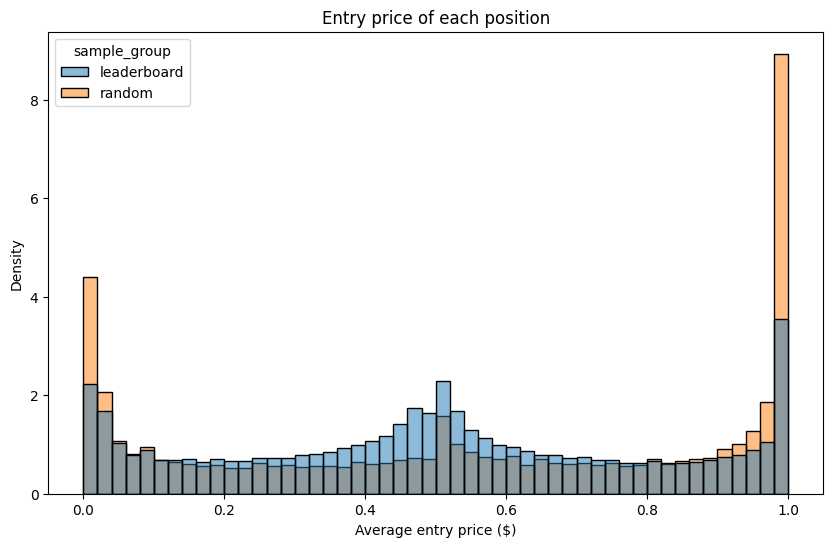

In [35]:
# Distribution of entry prices by group
sns.histplot(data=positions_clean_df, x='avg_price', hue='sample_group', bins=50,
             stat='density', common_norm=False)
plt.title('Entry price of each position')
plt.xlabel('Average entry price ($)')
plt.show()

Observations: 	Both groups tend to buy shares when the position has at least 98% chance of resolving as "Yes," but this is far more common for wallets from the random group. Both groups also buy more for high-risk positions, where the entry price is less than \$0.02, but the once again density is more than twice as high for wallets from the random group than that of the leaderboard group. There's also a small bump for both groups in the medium risk range, where the entry price is \$0.50, but the density for leaderboard wallets is slightly higher than that of wallets from the random group. Overall, it seems that the random group of wallets tends to buy positions at more extremes than leaderboard wallets do, while leaderboard wallets buy more from the middle.

Number of positions in each price group, for each sample group.

In [36]:
# Leaderboard: number and percent of positions in each price group
duckdb.sql("SELECT price_group, COUNT(*) AS positions, \
ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM positions_clean_df \
WHERE sample_group = 'leaderboard'), 1) AS percent FROM positions_clean_df \
WHERE sample_group = 'leaderboard' GROUP BY price_group ORDER BY price_group").df()

,price_group,positions,percent
0,highRisk,62298,19.8
1,lowRisk,64604,20.5
2,mediumRisk,188198,59.7


In [37]:
# Random: number and percent of positions in each price group
duckdb.sql("SELECT price_group, COUNT(*) AS positions, \
ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM positions_clean_df \
WHERE sample_group = 'random'), 1) AS percent FROM positions_clean_df \
WHERE sample_group = 'random' GROUP BY price_group ORDER BY price_group").df()

,price_group,positions,percent
0,highRisk,64528,24.4
1,lowRisk,91918,34.8
2,mediumRisk,107614,40.8


Observations: At first, we were confused that the number of high risk positions by the leaderboard group was higher than that of the random group, but then we remembered that this is because wallets from the leaderboard group tend to purchase more positions.

The tables show that medium risk positions make up about 60% of the purchases for leaderboard groups. They also make up quite a significant portion of purchases for wallets from the random group, but not nearly as much (about 41.4%). The tables also confirm that wallets from the random group tend to buy more at extremes than leaderboard wallets do (~58.6 compared to ~39.9%).

### 5. Categories
Category is a control variable in our position model and the basis of CategoryHHI. We check how many positions fall in each category and whether average returns differ by category. The black lines are 95% confidence intervals.

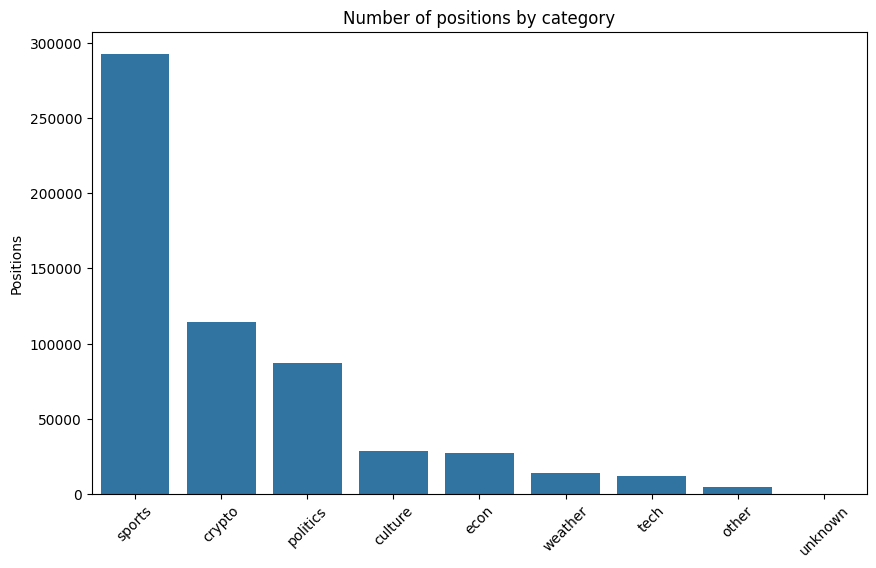

In [38]:
# Number of positions in each category
category_counts = positions_clean_df['category'].value_counts().reset_index()
sns.barplot(data=category_counts, x='category', y='count')
plt.title('Number of positions by category')
plt.xlabel('')
plt.ylabel('Positions')
plt.xticks(rotation=45)
plt.show()

Observations: The sports category has overwhelmingly the largest number of positions, followed by crypto and politics, both of which are less than half the amount of positions in sports. Culture and economics, which appear to be somewhat evenly matched, are both less than half the size of the number of positions in politics. Positions categorized as "other" make up the smallest number.

Average ROI by category. ROI is capped at the 1st and 99th percentiles so that one huge win cannot dominate a bar.

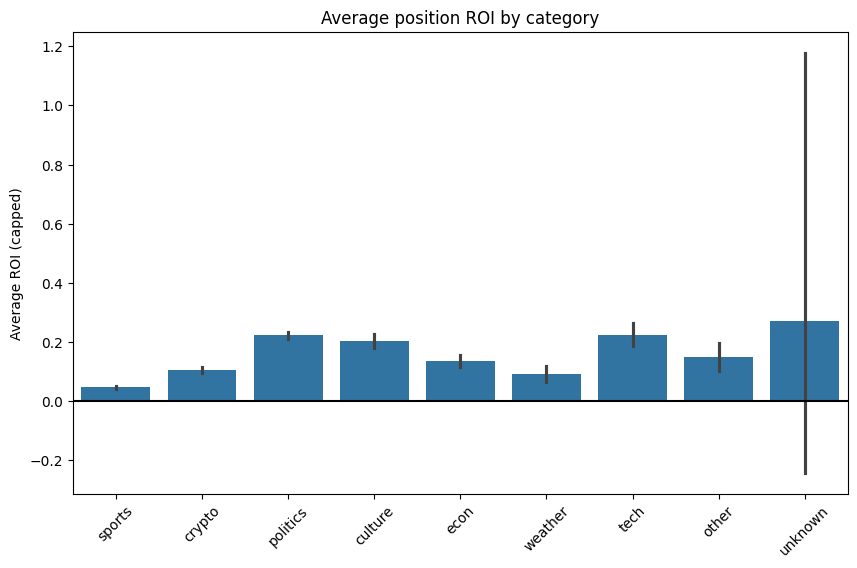

In [39]:
# Average ROI by category (ROI capped at the 1st and 99th percentiles)
roi_1 = positions_clean_df['roi'].quantile(0.01)
positions_clean_df['roi_capped'] = positions_clean_df['roi'].clip(roi_1, roi_99)
sns.barplot(data=positions_clean_df, x='category', y='roi_capped', order=category_counts['category'])
plt.axhline(0, color='black')
plt.title('Average position ROI by category')
plt.xlabel('')
plt.ylabel('Average ROI (capped)')
plt.xticks(rotation=45)
plt.show()

Observations: Despite being the category with the most positions, sports has the lowest ROI, followed by crypto. On the other hand, technology, politics, and culture have the highest average ROI, but their confidence intervals overlap, so we cannot say for certain which of the three is the highest. The confidence interval for technology is wider because it has fewer positions. We suspect that every category's average is positive because a small number of large wins on cheap contracts pull the averages up.

"Unknown" shows a large average ROI with a very wide confidence interval because it contains very few positions (under 0.1% of our data), so we draw no conclusions from it.

### 6. Holding time
Holding time is in our position model. We expect huge differences, from minutes (sports and crypto) to months (elections), which would mean we should use a log scale.

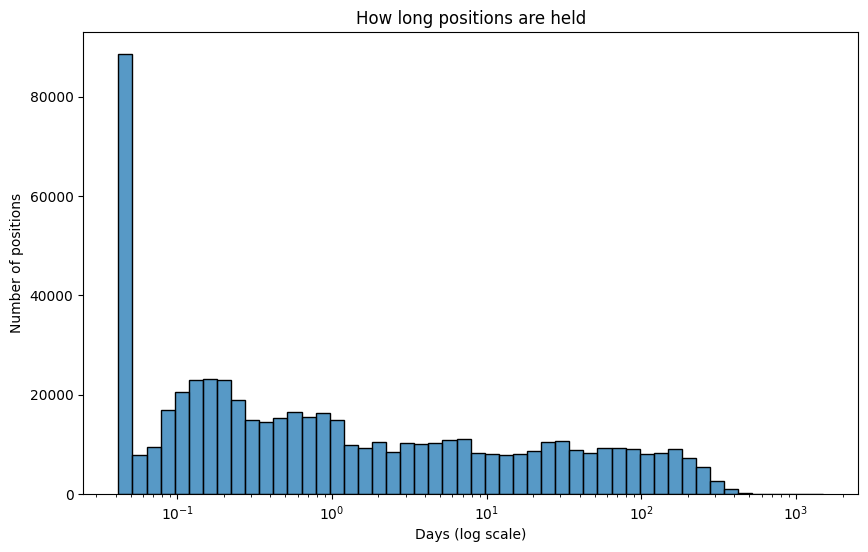

In [40]:
# Distribution of holding time (log scale; minimum one hour so the log works)
holding = positions_clean_df['holding_days'].dropna().clip(lower=1/24)
sns.histplot(x=holding, log_scale=True, bins=50)
plt.title('How long positions are held')
plt.xlabel('Days (log scale)')
plt.ylabel('Number of positions')
plt.show()

Observations: Holding times range from under an hour to more than a year, so we used a log scale. On this plot each step on the x-axis is 10 times longer than the one before, because base 10 is easier to read on an axis; in the model itself we use the natural log. The tall bar on the far left is about 88,000 positions (about 15% of all positions) held for less than an hour, which we grouped into one bar so the log scale works. We do the same in the model: holding times under one hour are set to one hour before taking the log. We suspect many of these come from bots or from markets that resolve very quickly. There is another bump between about 2 and 7 hours, which could be sports games or short crypto markets that resolve within the same day. After about one day, the number of positions stays fairly flat up to 200 days, then drops off quickly after a year. This wide range suggests we should use the log of holding time in our position model.

### 7. Risk and category focus
**Why:** highRiskShare (risk) and CategoryHHI (focus) are our two main trader-level variables. They need to vary across traders in **both** groups, or they cannot explain differences in ROI.

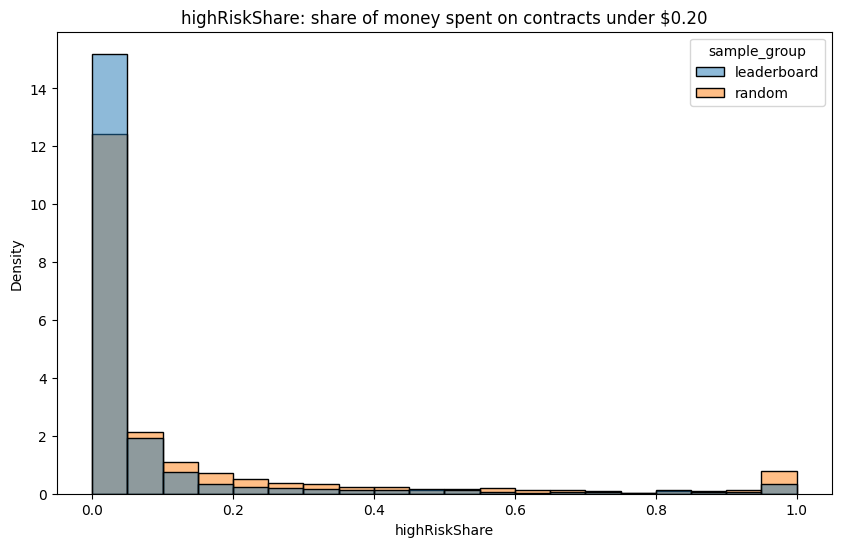

In [41]:
# highRiskShare by group
sns.histplot(data=traders_clean_df, x='highRisk_share', hue='sample_group', bins=20,
             stat='density', common_norm=False)
plt.title('highRiskShare: share of money spent on contracts under $0.20')
plt.xlabel('highRiskShare')
plt.show()

Observations: The distribution of highRiskShare is very right skewed in both groups: most wallets spend very little of their money on high risk positions (contracts under $0.20), and only a few spend a lot. About three quarters of leaderboard wallets and about two thirds of wallets from the random group spend less than 5% of their money on them. Wallets from the random group are more spread out: more of them spend between 10% and 40% of their money on high risk positions, and about 4% of them spend almost all of their money there, compared to about 2% of leaderboard wallets. This matches the entry price plot, where wallets from the random group bought more at the extremes. Overall, risk-taking does vary in both groups, but only a small number of wallets take a lot of risk.

CategoryHHI by group (1 = all money in one category).

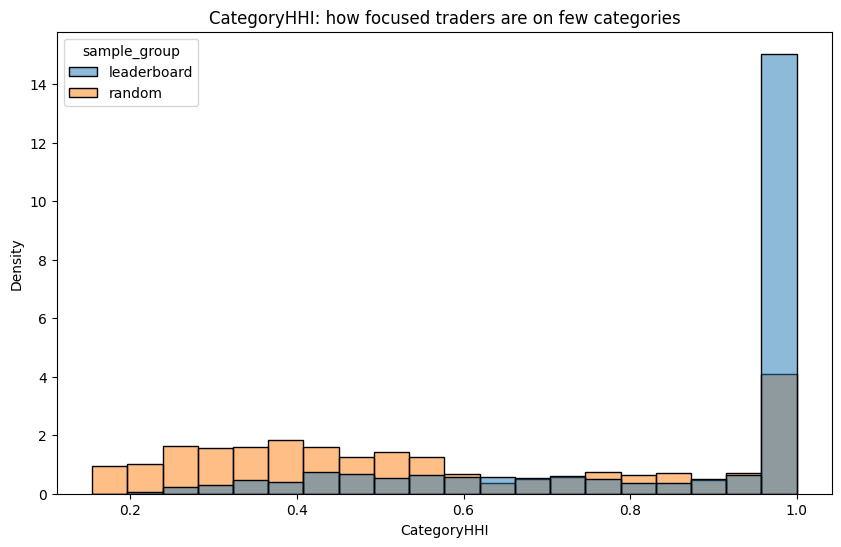

In [42]:
# CategoryHHI by group
sns.histplot(data=traders_clean_df, x='category_hhi', hue='sample_group', bins=20,
             stat='density', common_norm=False)
plt.title('CategoryHHI: how focused traders are on few categories')
plt.xlabel('CategoryHHI')
plt.show()

Observations: Wallets in the leaderboard overwhelmingly tend to focus on only one category. Wallets from the random group also focus more on one category, but not nearly as much as leaderboard wallets do. More wallets from the random group tend to spread their positions out than those of the leaderboard group.

### 8. Correlations between trader variables
**Why:** if two variables in the trader model are very strongly correlated (for example, number of positions and money spent), their coefficients become unreliable, and we may need to drop one.

In [43]:
# Correlation matrix of the trader-level variables (total spent on the natural log scale, as in the model)
traders_clean_df['log_total_spent'] = np.log(traders_clean_df['total_spent'])
corr_df = traders_clean_df[['highRisk_share', 'category_hhi', 'positions_per_month', 'tenure_months','log_total_spent', 'median_holding_days', 'top_trader']].corr()
corr_df

,highRisk_share,category_hhi,positions_per_month,tenure_months,log_total_spent,median_holding_days,top_trader
highRisk_share,1.000000,-0.147916,-0.129955,0.004232,-0.296252,0.078146,-0.128103
category_hhi,-0.147916,1.000000,0.093697,-0.250908,0.375612,-0.139719,0.493323
positions_per_month,-0.129955,0.093697,1.000000,0.031459,0.374424,-0.164822,0.155294
tenure_months,0.004232,-0.250908,0.031459,1.000000,-0.090186,0.237190,-0.144315
log_total_spent,-0.296252,0.375612,0.374424,-0.090186,1.000000,-0.203354,0.717950
median_holding_days,0.078146,-0.139719,-0.164822,0.237190,-0.203354,1.000000,-0.069561
top_trader,-0.128103,0.493323,0.155294,-0.144315,0.717950,-0.069561,1.000000


Observations: None of the trader variables are strongly correlated with each other. The strongest correlation is between category_hhi and top_trader (0.49), which matches the HHI plot: leaderboard wallets tend to focus on fewer categories. Tenure is negatively correlated with category_hhi (−0.25) and positively correlated with median holding days (0.23), so wallets that have been on Polymarket longer tend to spread across more categories and hold their positions longer. highRisk_share is only weakly correlated with every other variable (between −0.15 and 0.08), so it measures something the other variables don't. Since no correlation is above 0.5, we don't need to drop any variables from the trader model.

# __SOURCES__

**Polymarket Data**

Leaderboard, trades, positions, and user stats endpoints - https://docs.polymarket.com/api-reference/data-api/overview

Parameter names and response fields - https://data-api.polymarket.com/v2/docs

Closed-event filters, tags, and volume - https://docs.polymarket.com/api-reference/events/list-events.md



**Other Sources**

General information on Polymarket - https://www.britannica.com/money/Polymarket

CASE...WHEN...THEN... - https://duckdb.org/docs/current/sql/expressions/case

requests - https://requests.readthedocs.io/en/latest/

enumerate - https://www.geeksforgeeks.org/python/enumerate-in-python/

seaborn histogram - https://seaborn.pydata.org/generated/seaborn.histplot.html

Herfindahl-Hirschman Index - https://www.investopedia.com/terms/h/hhi.asp

axhline - https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.axhline.html

quantile - https://pandas.pydata.org/docs/reference/api/pandas.Series.quantile.html

clip - https://pandas.pydata.org/docs/reference/api/pandas.Series.clip.html


# __QUESTIONS FOR REVIEWERS__
- As mentioned in our limitations section, our missing data is not spread evenly. Is it sufficient to acknowledge this as a limitation or is there some other action we must take?
- We made a judgment call to label positions under \$0.20 "highRisk" and \$0.80 or more "lowRisk." Are these reasonable cutoffs?
- Is our notebook readable? We have large blocks of text at some parts because we wanted to explain things clearly, but we're not sure if this is overwhelming to look at.
- Are there other factors or predictors we could consider in our models that could be relevant to trading behaviors and ROI?
- Are the concepts understandable, especially for people who don't have experience with prediction markets?